In [2]:
import os
import time
import matplotlib.pyplot as plt
import pandas as pd
import requests
from IPython.display import display
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import json
from pathlib import Path
from matplotlib.ticker import PercentFormatter

# Quarterly cash capex, 2016–2026

Combined capital spending for Microsoft (MSFT), Alphabet (GOOG), Amazon (AMZN), Meta (META), and Oracle (ORCL), in billions of US dollars.

The measure is cash paid for property and equipment, generally before asset-sale proceeds. The notebook recovers standalone quarters from fiscal year-to-date cash flows and groups them by the calendar quarter containing each fiscal quarter-end. Oracle’s fiscal quarters end in February, May, August, and November, so its reporting periods are offset by a month. A bar appears only when all five companies have reported.

The notebook uses 10-K and 10-Q data from the [SEC EDGAR Company Facts API](https://www.sec.gov/search-filings/edgar-application-programming-interfaces). For Amazon 2017 Q2, the API lacks a standalone or six-month purchases value, so the notebook uses the $2.501 billion reported on the net purchases line in [Amazon’s original 10-Q](https://www.sec.gov/Archives/edgar/data/1018724/000101872417000100/amzn-20170630x10q.htm) if the API still has a gap.


In [2]:
COMPANIES = {
    "MSFT": "0000789019",
    "GOOG": "0001652044",
    "AMZN": "0001018724",
    "META": "0001326801",
    "ORCL": "0001341439",
}
PPE = "PaymentsToAcquirePropertyPlantAndEquipment"
PRODUCTIVE_ASSETS = "PaymentsToAcquireProductiveAssets"
QUARTERS = pd.period_range("2016Q1", "2026Q4", freq="Q-DEC")

In [3]:
cwd = Path.cwd()
capex_data_dir = cwd / "data/capex"
capex_data_dir.mkdir(parents=True, exist_ok=True)
with requests.Session() as session:
    session.headers["User-Agent"] = "dataviz project grizzlybears@unige s4801634@studenti.unige.it"
    session.mount("https://", HTTPAdapter(max_retries=Retry(
        total=3, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504]
    )))
    for ticker, cik in COMPANIES.items():
        cache_path = capex_data_dir / f"{ticker}.json"
        if cache_path.exists():
            print(f"Using cached SEC data for {ticker}: {cache_path.relative_to(cwd)}")
            continue
        url = f"https://data.sec.gov/api/xbrl/companyfacts/CIK{cik}.json"
        response = session.get(url, timeout=30)
        response.raise_for_status()
        cache_path.write_text(json.dumps(response.json(), indent=2) + "\n", encoding="utf-8")
        print(f"Saved SEC data for {ticker}: {cache_path.relative_to(cwd)}")
        time.sleep(0.15)

Using cached SEC data for MSFT: data/capex/MSFT.json
Using cached SEC data for GOOG: data/capex/GOOG.json
Using cached SEC data for AMZN: data/capex/AMZN.json
Using cached SEC data for META: data/capex/META.json
Using cached SEC data for ORCL: data/capex/ORCL.json


In [4]:
company_facts = {
    ticker: json.loads((capex_data_dir / f"{ticker}.json").read_text(encoding="utf-8"))["facts"]["us-gaap"]
    for ticker in COMPANIES
}

## Convert cumulative cash flows to quarterly spending

For each XBRL tag and reporting period, use the most recently filed value. Subtract the previous fiscal quarter’s year-to-date value from the current one when both share the same fiscal-year start. The first quarter already covers three months. The fourth quarter is the annual value minus the nine-month value. A directly reported three-month fact also works when a cumulative pair is unavailable.

In [5]:
def quarterly_capex(concept):
    rows = [
        fact for fact in concept.get("units", {}).get("USD", [])
        if fact.get("start") and fact["form"] in {"10-Q", "10-K", "10-Q/A", "10-K/A"}
    ]
    if not rows:
        return pd.Series(dtype="float64")

    facts = pd.DataFrame(rows)
    facts[["start", "end"]] = facts[["start", "end"]].apply(pd.to_datetime)
    facts = facts.sort_values(["filed", "accn"]).drop_duplicates(["start", "end"], keep="last")
    facts["days"] = (facts["end"] - facts["start"]).dt.days + 1
    direct = facts.loc[facts["days"].between(75, 105)].set_index("end")["val"]
    if direct.index.has_duplicates:
        raise ValueError("Multiple three-month facts share a quarter-end.")

    fiscal_ytd = facts.loc[facts["days"].between(75, 380)].sort_values(["start", "end"]).copy()
    by_year = fiscal_ytd.groupby("start")
    prior_end = by_year["end"].shift()
    prior_value = by_year["val"].shift()
    consecutive = (fiscal_ytd["end"] - prior_end).dt.days.between(75, 105)
    differences = fiscal_ytd.loc[consecutive].assign(
        quarterly=fiscal_ytd["val"] - prior_value
    ).set_index("end")["quarterly"]
    if differences.index.has_duplicates:
        raise ValueError("Multiple cumulative series share a quarter-end.")

    return differences.combine_first(direct).sort_index()


by_company = {}
for ticker, facts in company_facts.items():
    tags = (PRODUCTIVE_ASSETS, PPE) if ticker == "AMZN" else (PPE,)
    values = pd.Series(dtype="float64")
    for tag in tags:
        values = values.combine_first(quarterly_capex(facts.get(tag, {})))
    if values.empty:
        raise ValueError(f"No comparable capex facts for {ticker}.")

    values.index = pd.DatetimeIndex(values.index).to_period("Q-DEC")
    if values.index.has_duplicates:
        raise ValueError(f"Multiple fiscal quarter-ends in one calendar quarter for {ticker}.")
    by_company[ticker] = values.reindex(QUARTERS)

amazon_q2_2017 = pd.Period("2017Q2", freq="Q-DEC")
if pd.isna(by_company["AMZN"].loc[amazon_q2_2017]):
    # Amazon's 2017 Q2 10-Q reports $2,501 million in net purchases.
    by_company["AMZN"].loc[amazon_q2_2017] = 2_501_000_000

capex_billions = pd.DataFrame(by_company) / 1e9
capex_billions.index.name = "Calendar quarter"
capex_billions["Total"] = capex_billions.sum(axis=1, min_count=len(COMPANIES))
# display(capex_billions.round(2))

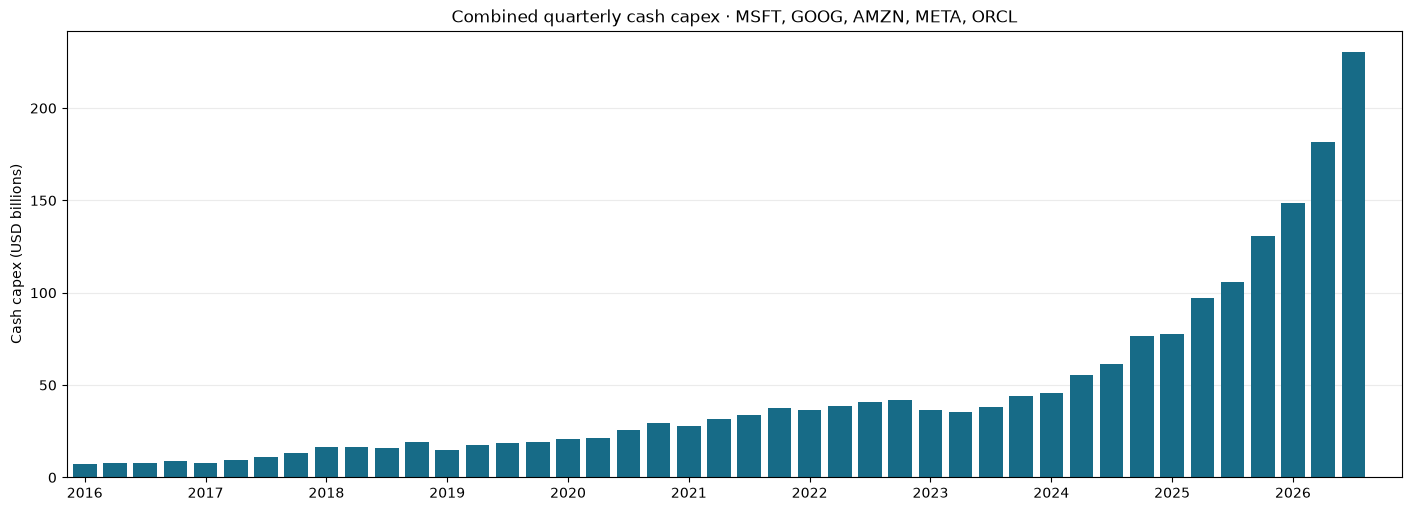

In [6]:
totals = capex_billions["Total"]
available = totals.notna()
if not available.any():
    raise ValueError("No quarter has capex data for all five companies.")

positions = range(len(totals))
year_ticks = [i for i, quarter in enumerate(totals.index) if quarter.quarter == 1]
fig, ax = plt.subplots(figsize=(14, 5), layout="constrained")
ax.bar(
    [i for i in positions if available.iloc[i]],
    totals[available],
    width=0.78,
    color="#176b87",
)
ax.set(
    title="Combined quarterly cash capex · MSFT, GOOG, AMZN, META, ORCL",
    ylabel="Cash capex (USD billions)",
    xlim=(-0.6, len(totals) - 0.4),
    ylim=(0, None),
)
ax.set_xticks(year_ticks, [str(totals.index[i].year) for i in year_ticks])
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
plt.show()

In [7]:
cwd = Path.cwd()
export_path = cwd / "src/data/quarterly-capex.json"
export_path.parent.mkdir(parents=True, exist_ok=True)
records = [
    {"quarter": str(quarter), "totalUsdBillions": None if pd.isna(value) else round(float(value), 6)}
    for quarter, value in capex_billions["Total"].items()
]
export_path.write_text(json.dumps(records, indent=2, allow_nan=False) + "\n", encoding="utf-8")
print(f"Wrote {len(records)} quarters to {export_path.relative_to(cwd)}")

Wrote 44 quarters to src/data/quarterly-capex.json


## Electricity production mix in the United States, China, and the EU

Each bar shows how a region generated its electricity that year. The notebook reads Ember’s original global CSV from `data/` and selects the United States, China, and the EU for 2015–2025. Shares are calculated from generation in TWh using individual sources. Net imports and aggregate categories are excluded. The EU uses the dataset’s regional total.

[Ember – Yearly Electricity Data (2026)](https://ember-energy.org/data/yearly-electricity-data/)

Ember compiles data from multi-country datasets (EIA, Eurostat, Energy Institute, UN) and national sources such as China’s National Bureau of Statistics.

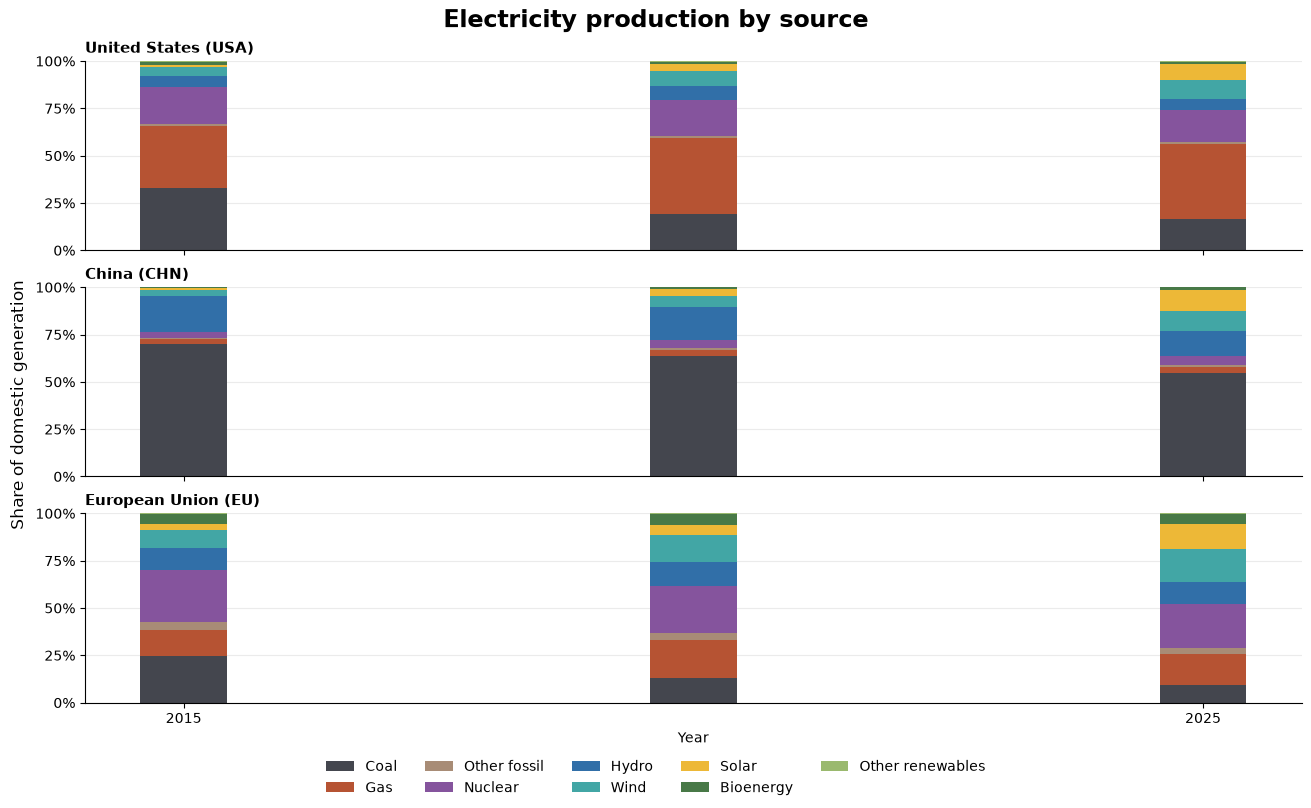

In [3]:
regions = {"United States": "United States (USA)", "China": "China (CHN)", "EU": "European Union (EU)"}
generation_raw = pd.read_csv(
    Path("data") / "ember_release_generation_yearly_global.csv",
    usecols=["Area", "Year", "Electricity source", "Is aggregated source", "Generation (TWh)"],
)
generation = generation_raw.loc[
    generation_raw["Area"].isin(regions)
    & generation_raw["Year"].isin([2015, 2020, 2025])
]

source_colors = {
    "Coal": "#44464e",
    "Gas": "#b65333",
    "Other fossil": "#a88c76",
    "Nuclear": "#85549d",
    "Hydro": "#316fa8",
    "Wind": "#42a6a5",
    "Solar": "#edb837",
    "Bioenergy": "#487947",
    "Other renewables": "#9ab96e",
}

domestic = generation.loc[
    generation["Area"].isin(regions)
    & generation["Is aggregated source"].eq(False)
    & generation["Electricity source"].ne("Net imports")
]
generation_by_source = domestic.pivot(
    index=["Area", "Year"], columns="Electricity source", values="Generation (TWh)"
).reindex(columns=list(source_colors)).fillna(0)

common_years = sorted(set.intersection(*[
    set(generation_by_source.loc[region].index) for region in regions
]))
generation_share = generation_by_source.div(generation_by_source.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True, sharey=True, layout="constrained")
fig.suptitle("Electricity production by source", fontsize=17, fontweight="bold")
for ax, (region, label) in zip(axes, regions.items()):
    mix = generation_share.loc[region].loc[common_years]
    bottom = pd.Series(0.0, index=mix.index)
    for electricity_source, color in source_colors.items():
        ax.bar(mix.index, mix[electricity_source], bottom=bottom, width=0.85,
               color=color, label=electricity_source)
        bottom += mix[electricity_source]
    ax.set_title(label, loc="left", fontsize=11, fontweight="bold")
    ax.set(ylim=(0, 100), yticks=[0, 25, 50, 75, 100])
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

axes[-1].set_xticks(sorted(set(common_years[::5]) | {common_years[-1]}))
axes[-1].set_xlabel("Year")
fig.supylabel("Share of domestic generation")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=5, frameon=False)
plt.show()

In [4]:
import json

generation_export = {
    "sources": [{"name": name, "color": color} for name, color in source_colors.items()],
    "regions": [
        {
            "name": label,
            "years": [
                {"year": int(year), "shares": shares.to_dict()}
                for year, shares in generation_share.loc[region].loc[common_years].iterrows()
            ],
        }
        for region, label in regions.items()
    ],
}

generation_export_path = Path("src/data/electricity-generation-mix.json")
generation_export_path.parent.mkdir(parents=True, exist_ok=True)
generation_export_path.write_text(
    json.dumps(generation_export, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
print(f"Wrote {generation_export_path}")


Wrote src/data/electricity-generation-mix.json


## Total electricity production

Compare annual domestic generation in TWh for the United States, China, and the EU over the same years as the mix chart. The grouped bars use Ember’s published `Total generation` rows for each region and year.

[Ember – Yearly Electricity Data (2026)](https://ember-energy.org/data/yearly-electricity-data/)

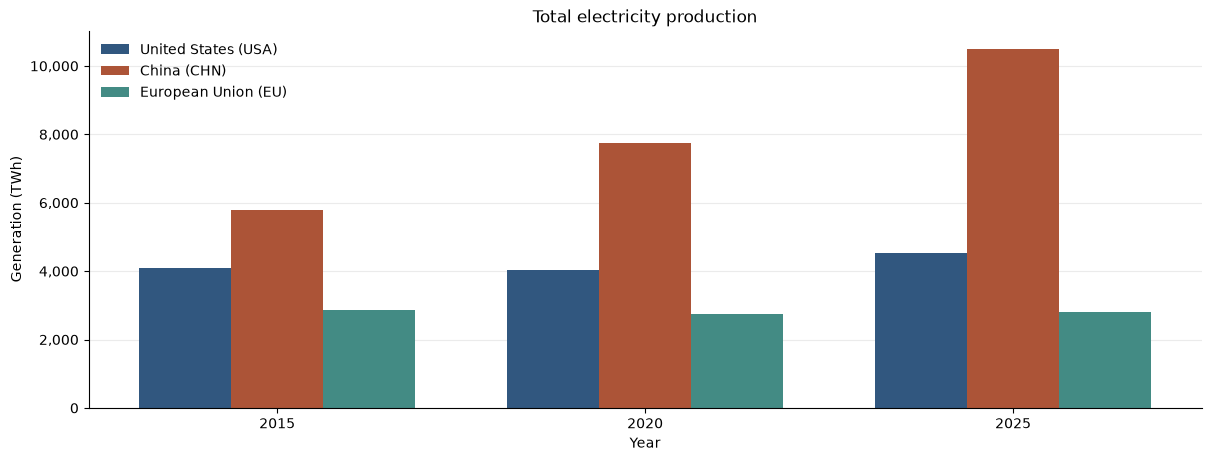

In [9]:
import numpy as np
from matplotlib.ticker import StrMethodFormatter

region_colors = {
    "United States": "#31577f",
    "China": "#ac5437",
    "EU": "#438b84",
}

totals = generation.loc[
    generation["Area"].isin(regions) & generation["Electricity source"].eq("Total generation")
].pivot(index="Year", columns="Area", values="Generation (TWh)")
totals = totals.loc[common_years, list(regions)]
if totals.isna().any().any():
    raise ValueError("Missing total generation for at least one region and year.")

positions = np.arange(len(totals))
bar_width = 0.25
fig, ax = plt.subplots(figsize=(12, 4.5), layout="constrained")
for i, (region, label) in enumerate(regions.items()):
    offset = (i - (len(regions) - 1) / 2) * bar_width
    ax.bar(positions + offset, totals[region], width=bar_width,
           color=region_colors[region], label=label)

ax.set(title="Total electricity production", xlabel="Year", ylabel="Generation (TWh)")
ax.set_xticks(positions, totals.index)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()


In [10]:
totals_export = [
    {
        "name": label,
        "color": region_colors[region],
        "years": [
            {"year": int(year), "totalTwh": float(total_twh)}
            for year, total_twh in totals[region].items()
        ],
    }
    for region, label in regions.items()
]

totals_export_path = Path("src/data/electricity-generation-totals.json")
totals_export_path.write_text(
    json.dumps(totals_export, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
print(f"Wrote {totals_export_path}")


Wrote src/data/electricity-generation-totals.json


## Critical minerals · production concentration in 2025

The heatmap compares the share of the leading country or region in mining and refining for each mineral. The 2025 shares are approximate readings from the IEA charts on pages 31–32, marked with ≈. For manganese mining, the IEA groups African countries together. Mining covers natural graphite, while refining covers battery-grade graphite. Rare earths refer to those used in magnets.

Source · [IEA, Global Critical Minerals Outlook 2026](https://www.iea.org/reports/global-critical-minerals-outlook-2026) · [Original PDF in this project](data/GlobalCriticalMineralsOutlook2026.pdf#page=31).


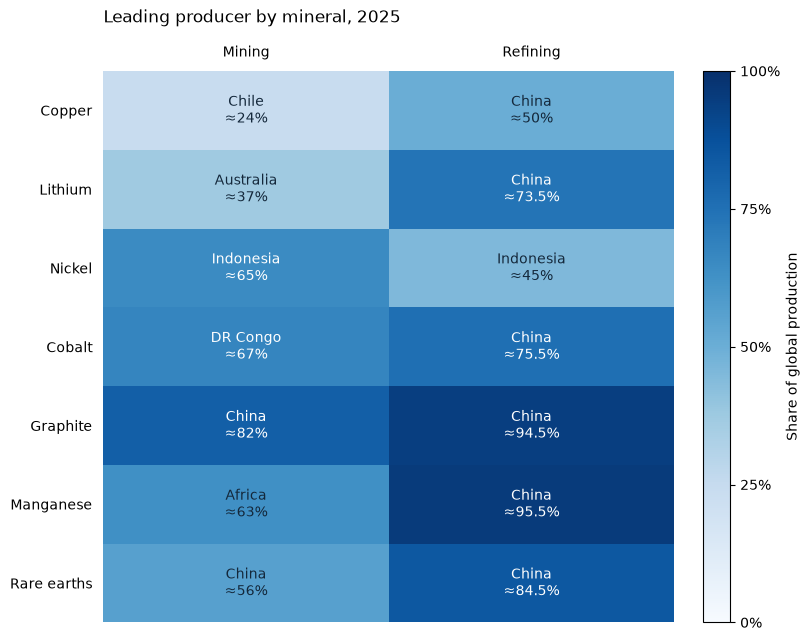

In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd

# Approximate shares from the IEA charts on mining (p. 32) and refining (p. 31).
mineral_production = pd.DataFrame(
    [
        ("Copper", "Chile", 24, "China", 50),
        ("Lithium", "Australia", 37, "China", 73.5),
        ("Nickel", "Indonesia", 65, "Indonesia", 45),
        ("Cobalt", "DR Congo", 67, "China", 75.5),
        ("Graphite", "China", 82, "China", 94.5),
        ("Manganese", "Africa", 63, "China", 95.5),
        ("Rare earths", "China", 56, "China", 84.5),
    ],
    columns=["Mineral", "Mining region", "Mining share (%)",
             "Refining region", "Refining share (%)"],
).set_index("Mineral")

stages = [
    ("Mining", "Mining region", "Mining share (%)"),
    ("Refining", "Refining region", "Refining share (%)"),
]
shares = mineral_production[[stage[2] for stage in stages]].to_numpy()

fig, ax = plt.subplots(figsize=(8, 6.3), layout="constrained")
heatmap = ax.imshow(shares, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_title("Leading producer by mineral, 2025", loc="left", pad=35)
ax.set_xticks(range(len(stages)), [stage[0] for stage in stages])
ax.set_yticks(range(len(mineral_production)), mineral_production.index)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False, length=0, pad=8)
ax.spines[:].set_visible(False)

for column, (_, area_field, share_field) in enumerate(stages):
    for row, (_, mineral) in enumerate(mineral_production.iterrows()):
        share = mineral[share_field]
        percent = f"{share:.1f}".removesuffix(".0")
        ax.text(column, row, f"{mineral[area_field]}\n≈{percent}%",
                ha="center", va="center", color="white" if share >= 65 else "#14283b")

colorbar = fig.colorbar(heatmap, ax=ax, format=PercentFormatter(100), ticks=[0, 25, 50, 75, 100])
colorbar.set_label("Share of global production")
plt.show()


In [7]:
import json
from pathlib import Path

minerals_export = [
    {
        "mineral": name,
        "mining": {"region": row["Mining region"], "share": float(row["Mining share (%)"])},
        "refining": {"region": row["Refining region"], "share": float(row["Refining share (%)"])},
    }
    for name, row in mineral_production.iterrows()
]

minerals_export_path = Path("src/data/critical-minerals-2025.json")
minerals_export_path.parent.mkdir(parents=True, exist_ok=True)
minerals_export_path.write_text(
    json.dumps(minerals_export, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
print(f"Wrote {minerals_export_path}")


Wrote src/data/critical-minerals-2025.json
